# 03 Problem 1 baselines
T4 GPU runtime. Train on SD1.4 only, test on all 8 generators.

Refs: ResNet (arXiv 1512.03385), CLIP (2103.00020), DINOv2 (2304.07193), UnivFD (2302.10174), Wang et al. 2020 (1912.11035)

In [1]:
# setup (same in every notebook)
import os, sys, subprocess

try:  # autoreload breaks on some Colab Python versions
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception:
    print("autoreload unavailable, restart runtime after pulling changes")

REPO_URL = "https://github.com/Devanshu1503/CV_project_genimage-detection.git"
REPO_DIR = "/content/CV_project_genimage-detection"

if "google.colab" in sys.modules:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    else:
        r = subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], capture_output=True, text=True)
        print("[setup] git pull:", (r.stdout or r.stderr).strip())
else:  # local run from notebooks/
    REPO_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.colab_setup import setup
cfg, P = setup()  # config dict + paths

autoreload unavailable, restart runtime after pulling changes
[setup] Python 3.13.16 | Colab: True | repo: /content/CV_project_genimage-detection
Mounted at /content/drive
[setup] all packages in requirements-colab.txt already installed (nothing reinstalled).
[setup] apt packages already installed: ['p7zip-full']
[setup] GPU: Tesla T4 | 15.6 GB | torch 2.11.0+cu130
[setup] seed = 42
[setup] Paths (colab):
  env            colab
  repo_root      /content/CV_project_genimage-detection
  genimage_root  /content/drive/MyDrive/genimage
  project_root   /content/drive/MyDrive/genimage_project
  work_dir       /content/work
  manifests      /content/drive/MyDrive/genimage_project/manifests
  raw_subset     /content/drive/MyDrive/genimage_project/raw_subset
  processed      /content/drive/MyDrive/genimage_project/processed
  features       /content/drive/MyDrive/genimage_project/features
  checkpoints    /content/drive/MyDrive/genimage_project/checkpoints
  results        /content/drive/MyDriv

## 1. GPU check

In [2]:
import torch

ALLOW_CPU = False   # CPU is way too slow, debug only
if torch.cuda.is_available():
    DEVICE = "cuda"
    print("GPU OK:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    msg = ("NO GPU FOUND. In Colab: Runtime -> Change runtime type -> T4 GPU, then Runtime -> Restart "
           "and run all again.")
    if not ALLOW_CPU:
        raise RuntimeError(msg)
    print("WARNING:", msg)

GPU OK: Tesla T4


In [3]:
import gc

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from torch.utils.data import DataLoader

from src import datasets as ds
from src import eda_utils as eu
from src import evaluate as ev
from src import models as mdl
from src import train as tr
from src.config import generator_names, get_logger

eu.set_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
log = get_logger("03_problem1_baselines", P.logs)
SEED = cfg["project"]["seed"]
NAMES = generator_names(cfg)
GEN_ORDER = [g["folder"] for g in cfg["generators"]]
TRAIN_GEN = cfg["train_generator"]
THR = cfg["evaluation"]["threshold"]
FEAT = cfg["features"]
RCFG = cfg["training"]["resnet50"]


def save(fig, name):
    eu.savefig(fig, f"03_{name}", P.figures)
    plt.show()


# fixed order so cached features line up
index = ds.load_index(P.manifests).sort_values("sample_id").reset_index(drop=True)
display(index.groupby(["split_set", "generator_name", "label"]).size().unstack("label"))

/content/CV_project_genimage-detection/src/datasets.py:17: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  idx = pd.read_csv(manifests_dir / "processed_index.csv")


label                       ai  nature
split_set generator_name              
test      ADM              500     500
          BigGAN           500     500
          GLIDE            500     500
          Midjourney       500     500
          SD1.4            500     500
          SD1.5            500     500
          VQDM             500     500
          Wukong           500     500
train     SD1.4           4000    4000
val       SD1.4           1000    1000

### Copy processed images to local disk
Way faster than reading from Drive every epoch.

In [4]:
if cfg["training"]["copy_processed_to_local"]:
    n = ds.stage_locally(index["processed_relpath"], P.project_root, P.work_dir)
    DATA_ROOT = P.work_dir
    print(f"Copied {n} new files; reading images from {DATA_ROOT}")
else:
    DATA_ROOT = P.project_root
masks = {s: (index["split_set"] == s).to_numpy() for s in ["train", "val", "test"]}
y_all = index["y"].to_numpy()

copy to local disk:   0%|          | 0/18000 [00:00<?, ?it/s]

Copied 18000 new files; reading images from /content/work


## 2. Challengers: frozen CLIP / DINOv2 + logistic regression
Features are cached in `features/`, C is tuned on SD1.4 val.

2026-11-04 02:02:00 | INFO | === CLIP ViT-L/14 + LR ===


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_projection.weight     

... (30 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4860755620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4860755620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

shard 9/9:   0%|          | 0/32 [00:00<?, ?it/s]

can only test a child process


dinov2 features: (18000, 768)
2026-11-04 02:09:07 | INFO |   C=0.0001: val AUROC=0.9128 acc=0.8270
2026-11-04 02:09:08 | INFO |   C=0.001: val AUROC=0.9321 acc=0.8560
2026-11-04 02:09:08 | INFO |   C=0.01: val AUROC=0.9369 acc=0.8575
2026-11-04 02:09:09 | INFO |   C=0.1: val AUROC=0.9344 acc=0.8525
2026-11-04 02:09:10 | INFO |   C=1: val AUROC=0.9333 acc=0.8525
2026-11-04 02:09:10 | INFO |   C=10: val AUROC=0.9331 acc=0.8505
Best C = 0.01; saved /content/drive/MyDrive/genimage_project/checkpoints/linear_probe_dinov2.joblib
[results] saved /content/drive/MyDrive/genimage_project/results/problem1_linear_probe_tuning.csv
[figure] saved /content/drive/MyDrive/genimage_project/figures/03_linear_probe_tuning.png


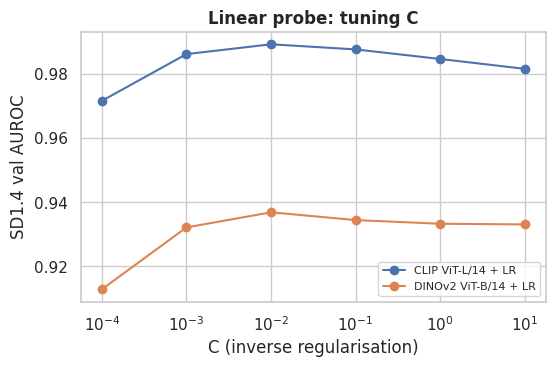

In [5]:
probe_preds, probe_tuning = [], []
for kind, model_name in [("clip", "CLIP ViT-L/14 + LR"), ("dinov2", "DINOv2 ViT-B/14 + LR")]:
    log.info(f"=== {model_name} ===")
    dset = ds.GenImageDataset(index, DATA_ROOT, ds.feature_transforms(kind, cfg["preprocess"]["image_size"]))
    extractor = mdl.build_feature_extractor(kind, cfg)
    X = mdl.extract_features_cached(extractor, dset, P.features / kind, batch_size=FEAT["batch_size"],
                                    shard_size=FEAT["shard_size"], num_workers=FEAT["num_workers"], device=DEVICE)
    del extractor
    gc.collect()
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
    print(f"{kind} features: {X.shape}")

    clf, tuning = tr.train_linear_probe(X[masks["train"]], y_all[masks["train"]], X[masks["val"]], y_all[masks["val"]],
                                        cfg["training"]["linear_probe"]["C_grid"],
                                        cfg["training"]["linear_probe"]["max_iter"], SEED, logger=log)
    tuning.insert(0, "model", model_name)
    probe_tuning.append(tuning)
    joblib.dump(clf, P.checkpoints / f"linear_probe_{kind}.joblib")
    best_C = tuning.loc[tuning["val_auroc"].idxmax(), "C"]
    print(f"Best C = {best_C}; saved {P.checkpoints / f'linear_probe_{kind}.joblib'}")

    ev_mask = masks["val"] | masks["test"]
    probe_preds.append(index.loc[ev_mask, ["sample_id", "generator", "split_set", "y"]]
                       .assign(model=model_name, score=clf.predict_proba(X[ev_mask])[:, 1]))

tuning_df = pd.concat(probe_tuning, ignore_index=True)
ev.save_table(tuning_df, P.results / "problem1_linear_probe_tuning.csv")
fig, ax = plt.subplots(figsize=(6, 3.5))
for m, g in tuning_df.groupby("model"):
    ax.plot(g["C"], g["val_auroc"], marker="o", label=m)
ax.set(xscale="log", xlabel="C (inverse regularisation)", ylabel="SD1.4 val AUROC", title="Linear probe: tuning C")
ax.legend(fontsize=8)
save(fig, "linear_probe_tuning")

## 3. Champion: fine-tuned ResNet-50
Random crop + flip only (JPEG aug is Problem 2), resumes from `last.pt`.

In [6]:
g = torch.Generator().manual_seed(SEED)
train_ds = ds.GenImageDataset(index.loc[masks["train"]], DATA_ROOT, ds.resnet_transforms(RCFG["crop_size"], train=True))
val_ds = ds.GenImageDataset(index.loc[masks["val"]], DATA_ROOT, ds.resnet_transforms(RCFG["crop_size"], train=False))
test_ds = ds.GenImageDataset(index.loc[masks["test"]], DATA_ROOT, ds.resnet_transforms(RCFG["crop_size"], train=False))
dl_kw = dict(batch_size=RCFG["batch_size"], num_workers=RCFG["num_workers"], pin_memory=DEVICE == "cuda")
train_dl = DataLoader(train_ds, shuffle=True, drop_last=True, generator=g, **dl_kw)
val_dl = DataLoader(val_ds, shuffle=False, **dl_kw)
test_dl = DataLoader(test_ds, shuffle=False, **dl_kw)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} images")

CKPT = P.checkpoints / "resnet50"
resnet = mdl.build_resnet50(RCFG["weights"])
history = tr.train_resnet(resnet, train_dl, val_dl, val_ds.df["y"].to_numpy(), CKPT, epochs=RCFG["epochs"],
                          lr=RCFG["lr"], weight_decay=RCFG["weight_decay"], patience=RCFG["early_stopping_patience"],
                          amp=RCFG["amp"], device=DEVICE, logger=log)
display(history)

train 8000 | val 2000 | test 8000 images
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


epoch 1/5:   0%|          | 0/125 [00:00<?, ?it/s]

predict:   0%|          | 0/32 [00:00<?, ?it/s]

2026-11-04 02:09:45 | INFO | epoch 1: train_loss=0.3611 val_loss=0.1618 val_auroc=0.9850 val_acc=0.9475 (32s)
2026-11-04 02:09:56 | INFO |   new best -> saved /content/drive/MyDrive/genimage_project/checkpoints/resnet50/best.pt


epoch 2/5:   0%|          | 0/125 [00:00<?, ?it/s]

... (8 outputs left out)

epoch 5/5:   0%|          | 0/125 [00:00<?, ?it/s]

predict:   0%|          | 0/32 [00:00<?, ?it/s]

2026-11-04 02:13:39 | INFO | epoch 5: train_loss=0.0214 val_loss=0.1015 val_auroc=0.9933 val_acc=0.9680 (38s)
2026-11-04 02:14:00 | INFO |   new best -> saved /content/drive/MyDrive/genimage_project/checkpoints/resnet50/best.pt


,epoch,train_loss,val_loss,val_auroc,val_acc,lr,seconds
0,1,0.361074,0.161827,0.984965,0.9475,0.000090,32.087084
1,2,0.115945,0.165740,0.986163,0.9365,0.000065,31.942239
2,3,0.052642,0.113556,0.992325,0.9620,0.000035,37.564345
3,4,0.030764,0.103637,0.993065,0.9655,0.000010,38.644587
4,5,0.021372,0.101508,0.993324,0.9680,0.000000,37.712614


[figure] saved /content/drive/MyDrive/genimage_project/figures/03_resnet50_training_curves.png


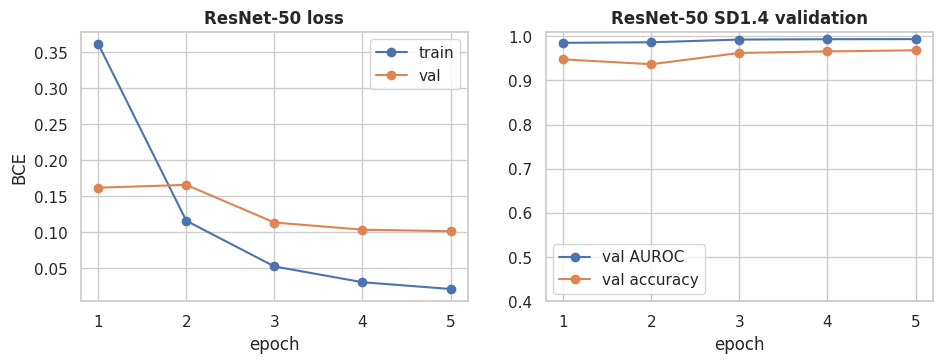

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="train")
axes[0].plot(history["epoch"], history["val_loss"], marker="o", label="val")
axes[0].set(title="ResNet-50 loss", xlabel="epoch", ylabel="BCE")
axes[0].legend()
axes[1].plot(history["epoch"], history["val_auroc"], marker="o", label="val AUROC")
axes[1].plot(history["epoch"], history["val_acc"], marker="o", label="val accuracy")
axes[1].set(title="ResNet-50 SD1.4 validation", xlabel="epoch", ylim=(0.4, 1.01))
axes[1].legend()
save(fig, "resnet50_training_curves")

In [8]:
# use best.pt, not the last epoch
best = torch.load(CKPT / "best.pt", map_location=DEVICE, weights_only=False)
resnet.load_state_dict(best["model"])
resnet.to(DEVICE)
print(f"Loaded best.pt from epoch {best['epoch'] + 1} (val AUROC {best['val_auroc']:.4f})")
resnet_preds = pd.concat([
    d.df[["sample_id", "generator", "split_set", "y"]].assign(
        model="ResNet-50 (fine-tuned)", score=tr.predict_scores(resnet, dl, DEVICE, RCFG["amp"]))
    for d, dl in [(val_ds, val_dl), (test_ds, test_dl)]], ignore_index=True)

Loaded best.pt from epoch 5 (val AUROC 0.9933)


predict:   0%|          | 0/32 [00:00<?, ?it/s]

predict:   0%|          | 0/125 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4860755620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4860755620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

## 4. Evaluation per generator
`mean_unseen` = average over the 7 generators not seen in training.

In [9]:
MODEL_ORDER = ["ResNet-50 (fine-tuned)", "CLIP ViT-L/14 + LR", "DINOv2 ViT-B/14 + LR"]
preds = pd.concat([resnet_preds] + probe_preds, ignore_index=True)
preds.to_csv(P.results / "problem1_predictions.csv", index=False)

val_res = ev.per_generator_table(preds.loc[preds["split_set"] == "val"], THR)
print("SD1.4 validation split (in-distribution, used for model selection):")
display(val_res[["model", "accuracy", "f1", "auroc", "real_acc", "fake_acc"]].round(4))

test_preds = preds.loc[preds["split_set"] == "test"]
results = ev.per_generator_table(test_preds, THR, GEN_ORDER, train_generator=TRAIN_GEN)
results.insert(2, "generator_name", results["generator"].map(NAMES).fillna(results["generator"]))
results["seen_in_training"] = results["generator"] == TRAIN_GEN
ev.save_table(results, P.results / "problem1_results.csv")

for metric in ["auroc", "accuracy", "f1", "real_acc", "fake_acc"]:
    piv = results.pivot(index="model", columns="generator_name", values=metric)
    piv = piv[[NAMES[g] for g in GEN_ORDER if NAMES[g] in piv.columns] + ["mean_unseen"]].reindex(MODEL_ORDER)
    print(f"\n{metric.upper()} (rows = models, columns = test generators; {NAMES[TRAIN_GEN]} was seen in training)")
    display(piv.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=1.0, axis=None))
    if metric == "auroc":
        piv.to_csv(P.results / "problem1_auroc_table.csv")

SD1.4 validation split (in-distribution, used for model selection):


,model,accuracy,f1,auroc,real_acc,fake_acc
0,ResNet-50 (fine-tuned),0.9680,0.9683,0.9933,0.960,0.976
1,CLIP ViT-L/14 + LR,0.9415,0.9419,0.9893,0.934,0.949
2,DINOv2 ViT-B/14 + LR,0.8575,0.8602,0.9369,0.838,0.877


[results] saved /content/drive/MyDrive/genimage_project/results/problem1_results.csv

AUROC (rows = models, columns = test generators; SD1.4 was seen in training)


generator_name,SD1.4,SD1.5,Midjourney,Wukong,ADM,GLIDE,VQDM,BigGAN,mean_unseen
model,,,,,,,,,
ResNet-50 (fine-tuned),0.991,0.995,0.833,0.989,0.624,0.615,0.613,0.424,0.728
CLIP ViT-L/14 + LR,0.985,0.987,0.930,0.946,0.756,0.871,0.735,0.646,0.839
DINOv2 ViT-B/14 + LR,0.935,0.937,0.870,0.914,0.526,0.721,0.584,0.397,0.707



ACCURACY (rows = models, columns = test generators; SD1.4 was seen in training)


generator_name,SD1.4,SD1.5,Midjourney,Wukong,ADM,GLIDE,VQDM,BigGAN,mean_unseen
model,,,,,,,,,
ResNet-50 (fine-tuned),0.957,0.974,0.700,0.946,0.511,0.520,0.534,0.485,0.667
CLIP ViT-L/14 + LR,0.937,0.933,0.827,0.868,0.625,0.755,0.594,0.521,0.732
DINOv2 ViT-B/14 + LR,0.856,0.877,0.782,0.843,0.506,0.627,0.558,0.469,0.666


... (2 outputs left out)


REAL_ACC (rows = models, columns = test generators; SD1.4 was seen in training)


generator_name,SD1.4,SD1.5,Midjourney,Wukong,ADM,GLIDE,VQDM,BigGAN,mean_unseen
model,,,,,,,,,
ResNet-50 (fine-tuned),0.954,0.974,0.946,0.966,0.948,0.944,0.962,0.960,0.957
CLIP ViT-L/14 + LR,0.922,0.928,0.934,0.926,0.940,0.928,0.940,0.938,0.933
DINOv2 ViT-B/14 + LR,0.838,0.876,0.860,0.848,0.854,0.810,0.856,0.878,0.855



FAKE_ACC (rows = models, columns = test generators; SD1.4 was seen in training)


generator_name,SD1.4,SD1.5,Midjourney,Wukong,ADM,GLIDE,VQDM,BigGAN,mean_unseen
model,,,,,,,,,
ResNet-50 (fine-tuned),0.960,0.974,0.454,0.926,0.074,0.096,0.106,0.010,0.377
CLIP ViT-L/14 + LR,0.952,0.938,0.720,0.810,0.310,0.582,0.248,0.104,0.530
DINOv2 ViT-B/14 + LR,0.874,0.878,0.704,0.838,0.158,0.444,0.260,0.060,0.477


[figure] saved /content/drive/MyDrive/genimage_project/figures/03_auroc_per_generator.png


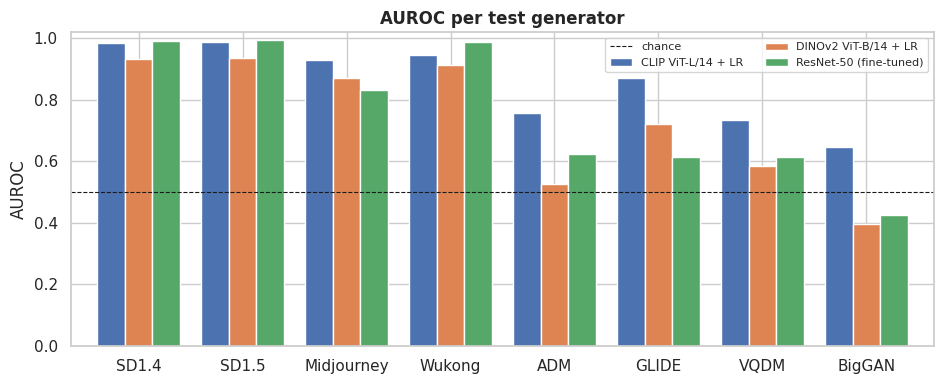

[figure] saved /content/drive/MyDrive/genimage_project/figures/03_accuracy_per_generator.png


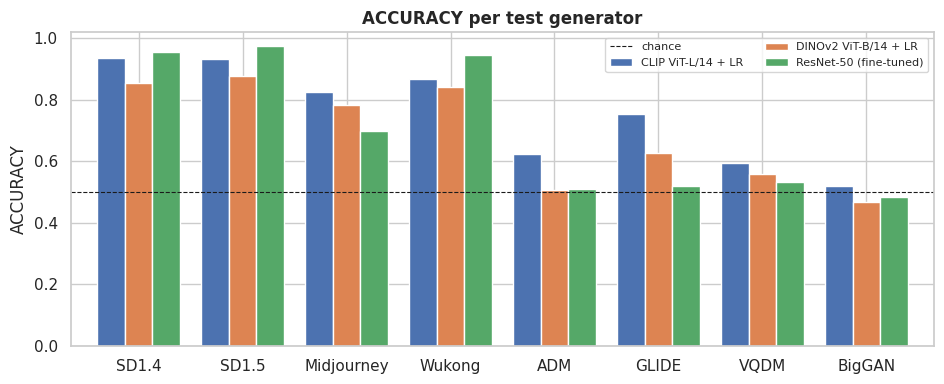

In [10]:
fig = ev.plot_metric_bars(results.loc[results["generator"] != "mean_unseen"], "auroc", GEN_ORDER, NAMES)
save(fig, "auroc_per_generator")
fig = ev.plot_metric_bars(results.loc[results["generator"] != "mean_unseen"], "accuracy", GEN_ORDER, NAMES)
save(fig, "accuracy_per_generator")

[figure] saved /content/drive/MyDrive/genimage_project/figures/03_roc_per_generator.png


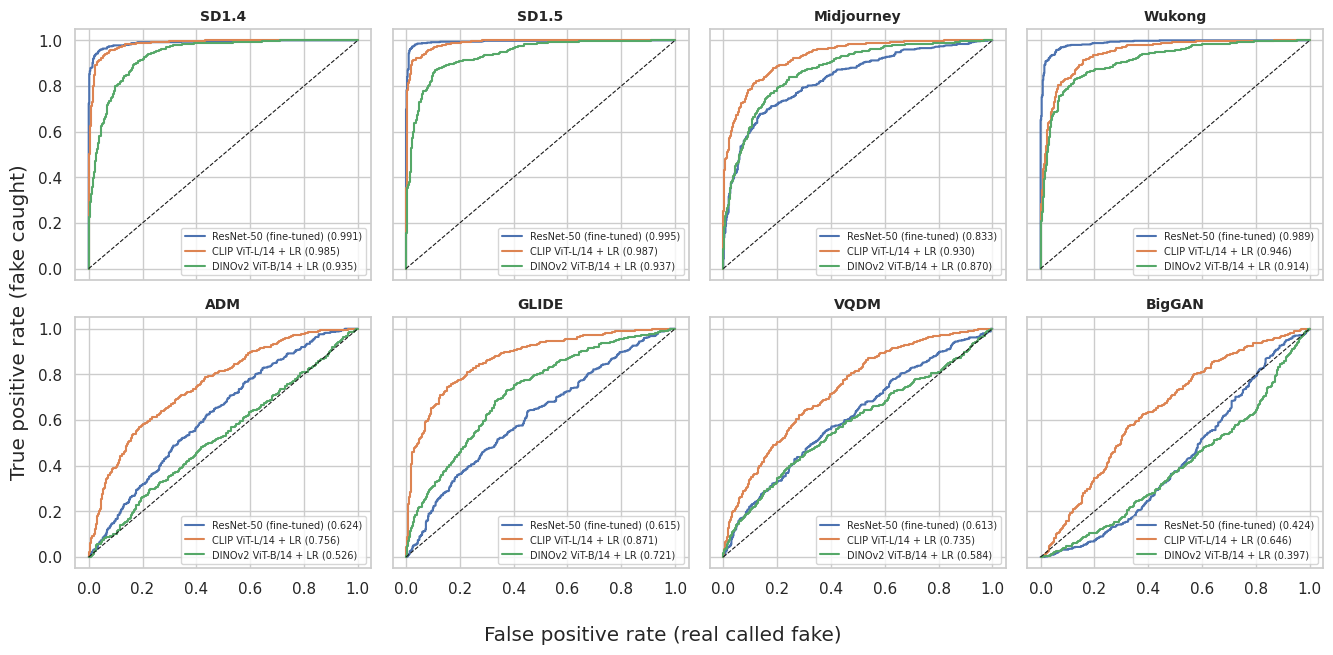

In [11]:
fig = ev.plot_roc_per_generator(test_preds, GEN_ORDER, names=NAMES)
save(fig, "roc_per_generator")

[figure] saved /content/drive/MyDrive/genimage_project/figures/03_confusion_resnet50.png


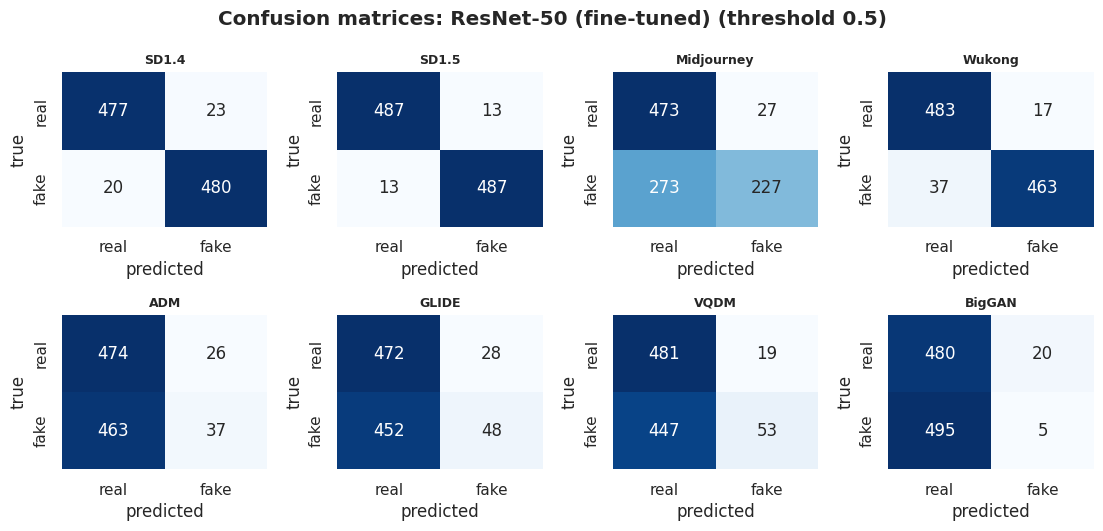

[figure] saved /content/drive/MyDrive/genimage_project/figures/03_confusion_clip.png


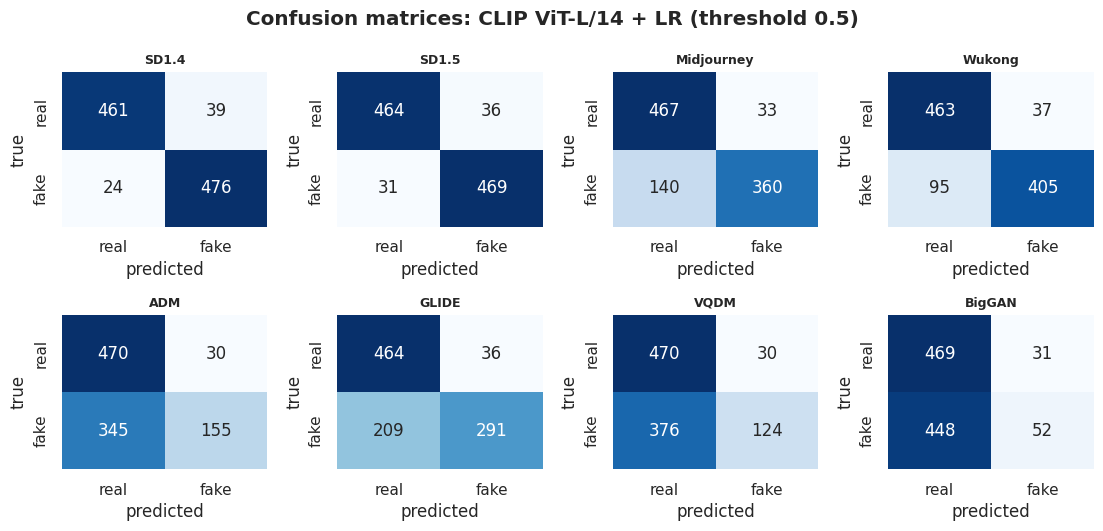

[figure] saved /content/drive/MyDrive/genimage_project/figures/03_confusion_dinov2.png


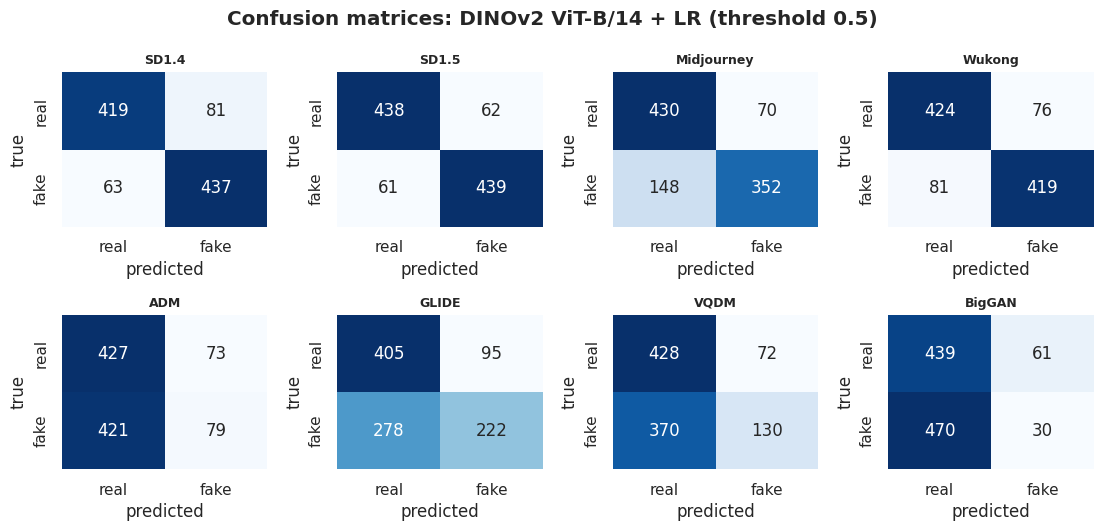

In [12]:
for m in MODEL_ORDER:
    fig = ev.plot_confusion_grid(test_preds, m, GEN_ORDER, THR, names=NAMES)
    save(fig, f"confusion_{m.split()[0].lower().replace('-', '')}")

[figure] saved /content/drive/MyDrive/genimage_project/figures/03_real_vs_fake_accuracy.png


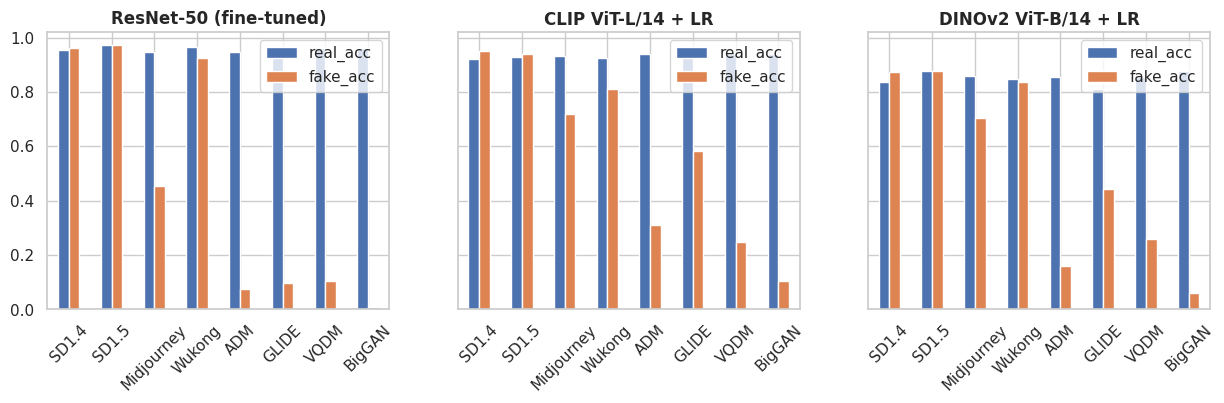

In [13]:
# where do the errors come from?
r = results.loc[results["generator"] != "mean_unseen"].copy()
fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(5 * len(MODEL_ORDER), 3.6), sharey=True)
for ax, m in zip(axes, MODEL_ORDER):
    g = r.loc[r["model"] == m].set_index("generator_name")[["real_acc", "fake_acc"]]
    g.reindex([NAMES[x] for x in GEN_ORDER]).plot.bar(ax=ax, color=[eu.REAL_COLOR, eu.FAKE_COLOR])
    ax.set(title=m, xlabel="", ylim=(0, 1.02))
    ax.tick_params(axis="x", rotation=45)
save(fig, "real_vs_fake_accuracy")

## 5. Model comparison (fill in)
- ResNet-50: learns low-level SD1.4 traces, might overfit to that generator.
- CLIP / DINOv2 probe: general pretrained features, only a linear layer is trained, may miss fine artifacts.
- Mean unseen AUROC per model:
- Hardest generators and why:
- Which one generalizes better:

## Findings (fill in after running)
- Training: epochs run, best epoch, val AUROC, training time per epoch:
- Linear probes: best C for CLIP / DINOv2, val AUROC:
- Per-generator AUROC highlights:
- Champion vs challengers on unseen generators:
- Surprises / failure cases (look at misclassified images):
- Next steps (see docs/NEXT_STEPS.md): Grad-CAM, robustness (Problem 2), raw-vs-processed training.

## Run before closing the tab
Uploads pending Drive writes, otherwise the next session may not see them.

In [14]:
from src.colab_setup import flush_drive
flush_drive()

[flush] Drive flushed and unmounted, safe to close the tab.
